In [101]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    # expit:이진분류,softmax:다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.model_selection import cross_validate,StratifiedKFold,GridSearchCV

In [102]:
#이정보를 가지고 피쳐에 대한 연봉예측 linearRegression구현


In [103]:
# 데이터 가져오기
picher = pd.read_csv('data/picher_stats_2017.csv')
picher.head(2)

,선수명,팀명,승,패,세,홀드,블론,경기,선발,이닝,...,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017)
0,켈리,SK,16,7,0,0,0,30,30,190.0,...,0.76,0.342,73.7,3.60,6.91,3.69,3.44,6.62,140000,85000
1,소사,LG,11,11,1,0,0,30,29,185.1,...,0.53,0.319,67.1,3.88,6.80,3.52,3.41,6.08,120000,50000


In [ ]:
# 데이터 분리
data = picher[picher.columns.difference(['선수명','팀명','연봉(2018)'])]
team = picher['팀명']
label = picher['연봉(2018)']                                


In [ ]:
# 원핫인코딩
from sklearn.preprocessing import OneHotEncoder

team = team.to_numpy().reshape(-1,1)
# 원핫인코딩 객체 생성 / NumPy 배열로 반환 / 0 부분 1개 삭제, True,False가 아닌 1,0
encoder = OneHotEncoder(sparse_output=False,drop='first', dtype=int)

# 원핫인코딩 적용
result = encoder.fit_transform(team)

# 숫자 데이터 + 원핫인코딩 결합
total_data = np.concatenate((data, result), axis=1)
total_data


array([[ 0.342,  3.6  ,  3.69 , ...,  0.   ,  0.   ,  0.   ],
       [ 0.319,  3.88 ,  3.52 , ...,  0.   ,  0.   ,  0.   ],
       [ 0.332,  3.44 ,  3.94 , ...,  0.   ,  0.   ,  0.   ],
       ...,
       [ 0.382, 11.66 ,  8.03 , ...,  1.   ,  0.   ,  0.   ],
       [ 0.341,  5.77 ,  6.87 , ...,  0.   ,  1.   ,  0.   ],
       [ 0.312,  7.67 ,  7.6  , ...,  0.   ,  0.   ,  0.   ]],
      shape=(152, 27))

In [106]:
train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)

In [107]:
#정규화
ss = StandardScaler()
ss.fit(train_data)
train_scaled =ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [108]:
# #데이터 학습
# lr = LinearRegression()
# lr.fit(train_data,train_label)
# #데이터 예측
# predict = lr.predict(test_scaled)
# print("예측",predict)

# #정확도
# score= lr.score(train_scaled,train_label)
# score2= lr.score(test_scaled,test_label)
# print('train정확도:',score)
# print('test정확도:',score2)

In [109]:
# 릿지규제 - alpha값을 바꿔가면서 정확도 확인
alpha_list = [0.001,0.01,0.1,1,10,100]
train_score = []
test_score = []
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    # 정확도
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)
print('완료')
print(train_score)
print(test_score)


완료
[0.9265400744146665, 0.9265055892367332, 0.9264208381731384, 0.9258799878343911, 0.9186505073335689, 0.8154372581424608]
[0.8306487325158969, 0.8325758107499632, 0.8364563658856817, 0.8457094418802562, 0.8357247390646219, 0.7000187660452177]


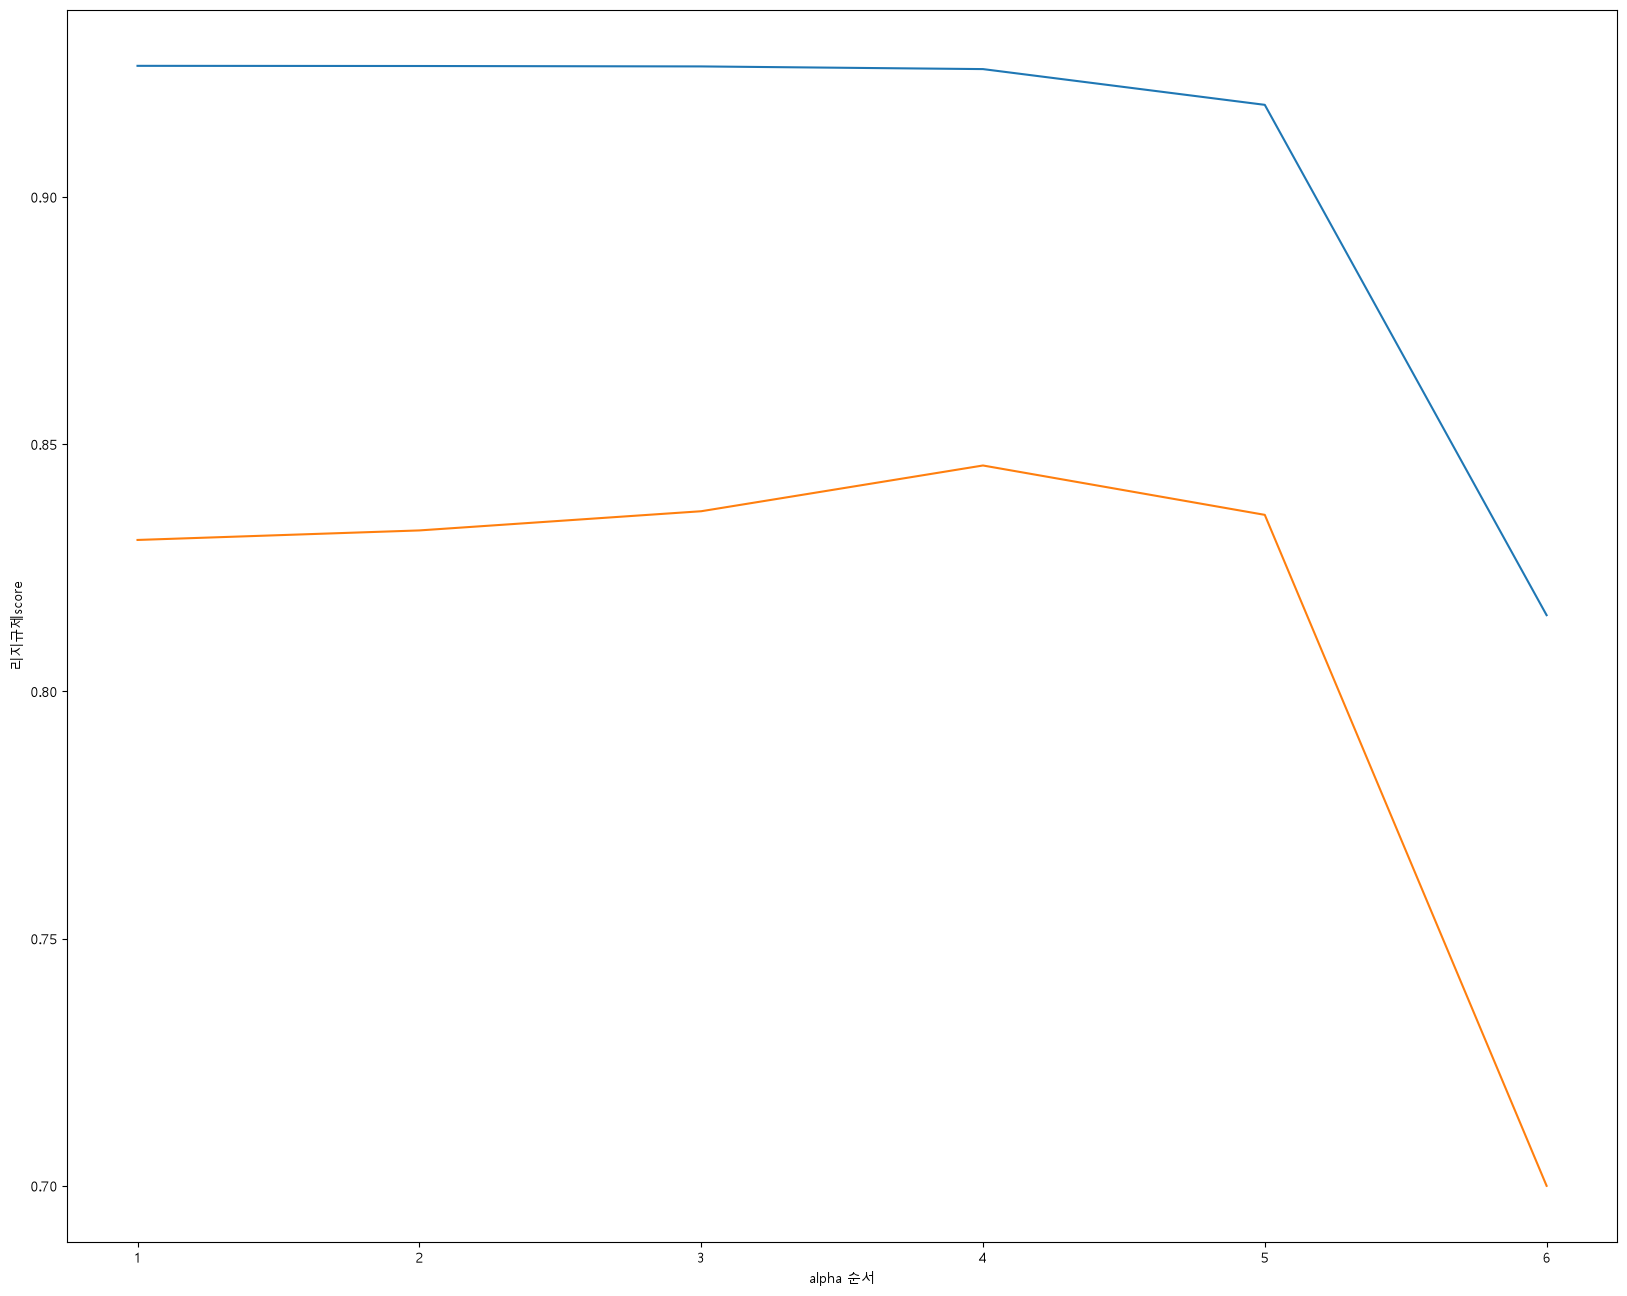

In [110]:
# 선그래프 - train,test 점수 차이가 가장 적고 test가 높은 alpha 찾기
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel('alpha 순서')
plt.ylabel('리지규제score')
plt.show()


In [111]:
# 가장 좋은 alpha로 다시 학습
ridge = Ridge(alpha=10)
model = ridge.fit(train_scaled,train_label)
# 정확도
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)
print('train정확도: ',score)
print('test정확도: ',score2)


train정확도:  0.9186505073335689
test정확도:  0.8357247390646219


In [115]:
data.columns

Index(['BABIP', 'ERA', 'FIP', 'LOB%', 'RA9-WAR', 'WAR', 'kFIP', '경기', '볼넷/9',
       '블론', '삼진/9', '선발', '세', '승', '연봉(2017)', '이닝', '패', '홀드', '홈런/9'],
      dtype='str')

In [112]:
# pip install statsmodels
# 회귀분석 통계결과표 : P>|t| 통계량의 절대값보다 크거나 같은 값이 나올 확률
import statsmodels.api as sm

train_scaled = sm.add_constant(train_scaled)
model = sm.OLS(train_label,train_scaled).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.927
Model:                            OLS   Adj. R-squared:                  0.912
Method:                 Least Squares   F-statistic:                     62.40
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           8.24e-45
Time:                        15:40:46   Log-Likelihood:                -1202.1
No. Observations:                 114   AIC:                             2444.
Df Residuals:                      94   BIC:                             2499.
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.986e+04    947.996     20.944      0.000     1.8e+04    2.17e+04
x1         -1292.4471   1404.417     -0.920      0.360   -4080.950    1496.056
x2           597.4391   2300.343      0.260      0.796   -3969.946    5164.825
x3         -3.331e+04   8.13e+04     -0.410      0.683   -1.95e+05    1.28e+05
x4          -555.9145   1856.439     -0.299      0.765   -4241.918    3130.089
x5         -1121.4314   3404.959     -0.329      0.743   -7882.058    5639.195
x6          1.232e+04   3079.843      3.999      0.000    6201.391    1.84e+04
x7          2.652e+04   7.24e+04      0.366      0.715   -1.17e+05     1.7e+05
x8         -4967.4258   3829.331     -1.297      0.198   -1.26e+04    2635.801
x9          4817.1138   5785.493      0.833      0.407   -6670.118    1.63e+04
x10         1020.7275   1572.765      0.649      0.518   -2102.035    4143.490
x11         -576.5203   6239.894     -0.092      0.927    -1.3e+04    1.18e+04
x12        -1.078e+04   6692.292     -1.611      0.111   -2.41e+04    2505.458
x13          227.4015   1544.643      0.147      0.883   -2839.523    3294.326
x14         4295.6930   2923.600      1.469      0.145   -1509.183    1.01e+04
x15         2.285e+04   1423.937     16.044      0.000       2e+04    2.57e+04
x16         9887.9635   8694.630      1.137      0.258   -7375.429    2.72e+04
x17        -1276.5256   2247.025     -0.568      0.571   -5738.047    3184.996
x18         -386.7810   1707.462     -0.227      0.821   -3776.986    3003.424
x19         8123.9644    1.3e+04      0.625      0.533   -1.77e+04    3.39e+04
==============================================================================
Omnibus:                       29.249   Durbin-Watson:                   1.820
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              336.558
Skew:                           0.007   Prob(JB):                     8.27e-74
Kurtosis:                      11.417   Cond. No.                         303.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

[Text(0, 0, 'const'),
 Text(1, 0, 'x1'),
 Text(2, 0, 'x2'),
 Text(3, 0, 'x3'),
 Text(4, 0, 'x4'),
 Text(5, 0, 'x5'),
 Text(6, 0, 'x6'),
 Text(7, 0, 'x7'),
 Text(8, 0, 'x8'),
 Text(9, 0, 'x9'),
 Text(10, 0, 'x10'),
 Text(11, 0, 'x11'),
 Text(12, 0, 'x12'),
 Text(13, 0, 'x13'),
 Text(14, 0, 'x14'),
 Text(15, 0, 'x15'),
 Text(16, 0, 'x16'),
 Text(17, 0, 'x17'),
 Text(18, 0, 'x18'),
 Text(19, 0, 'x19')]

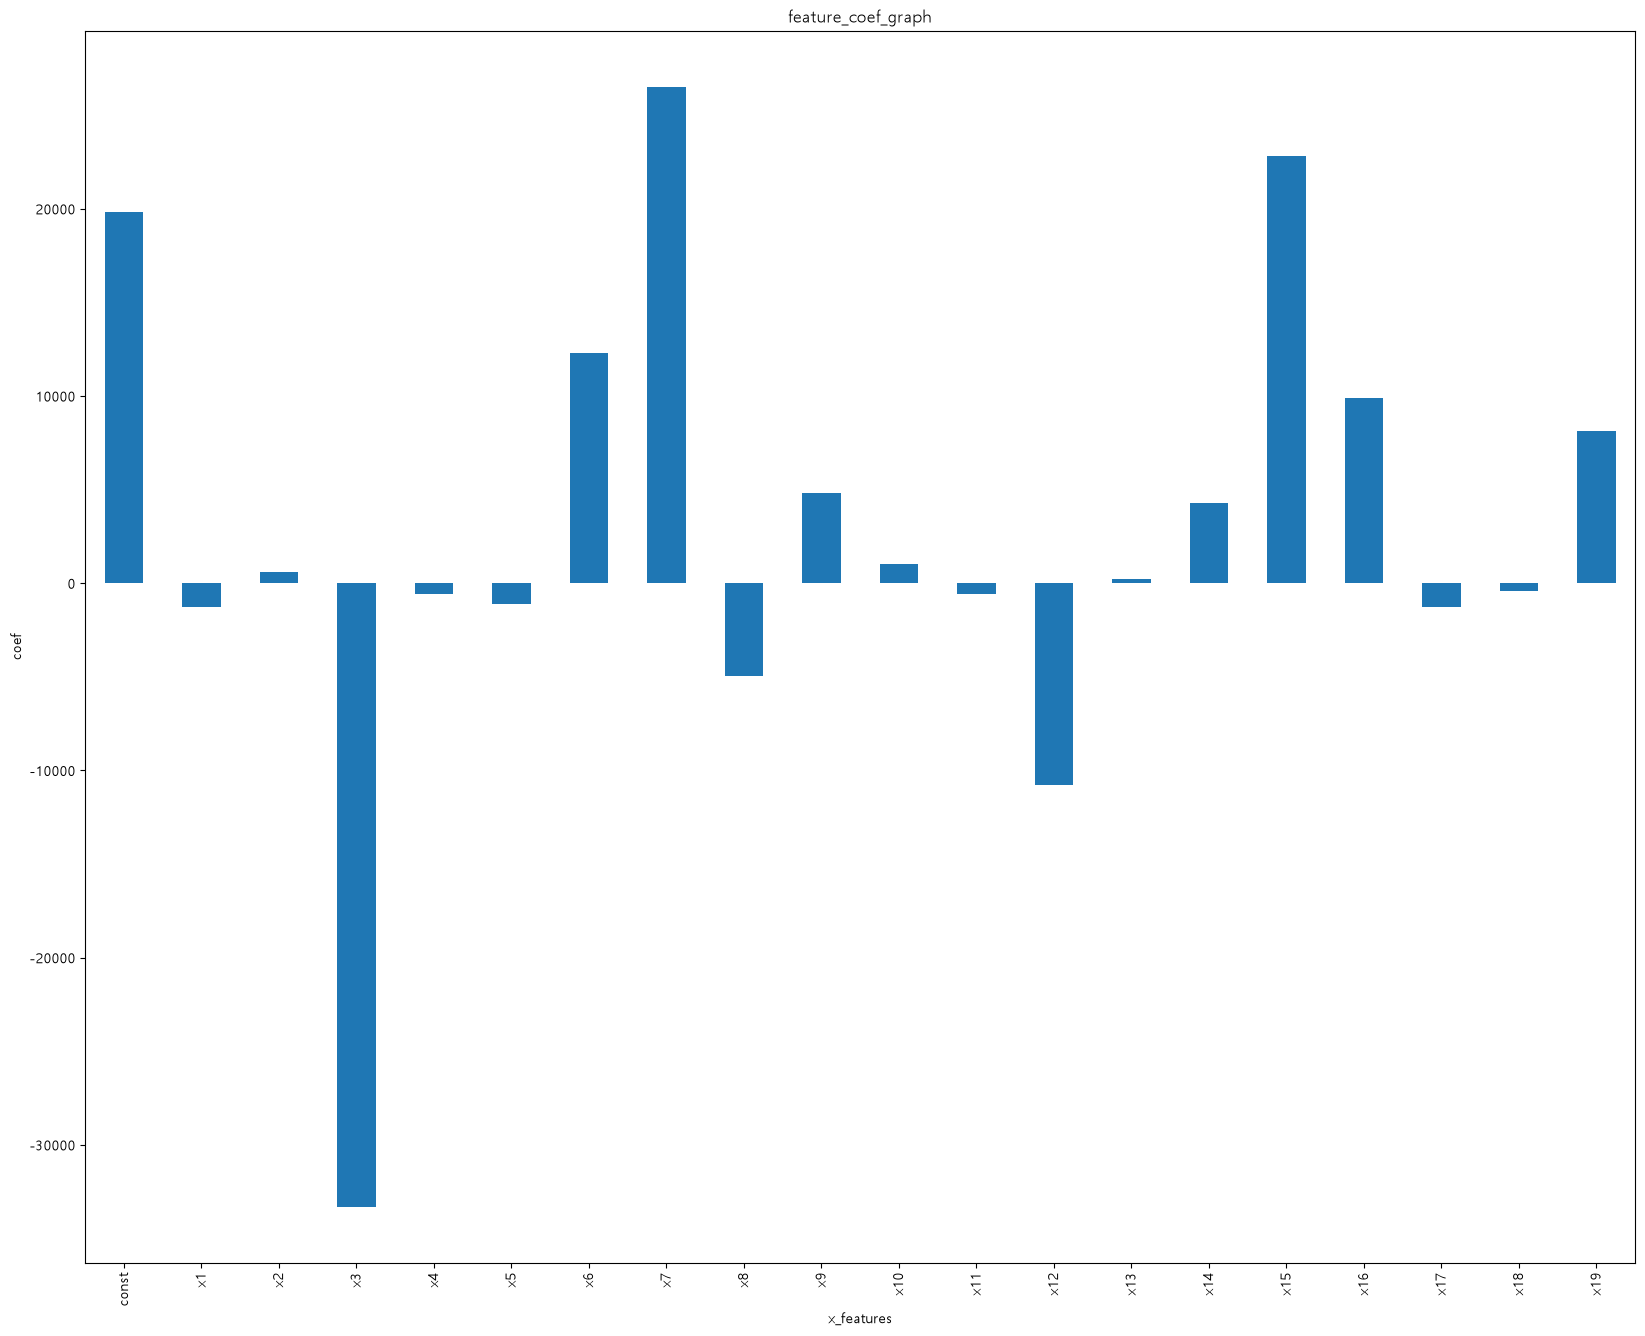

In [113]:
# 결정하는 결과에 영향을 미치는 것을 파악

plt.rcParams['figure.figsize'] = [20, 16]

# 회귀 계수를 리스트로 반환합니다.
coefs = model.params.tolist()
coefs_series = pd.Series(coefs)

# 변수명을 리스트로 반환합니다.
x_labels = model.params.index.tolist()

# 회귀 계수를 출력합니다.
ax = coefs_series.plot(kind='bar')
ax.set_title('feature_coef_graph')
ax.set_xlabel('x_features')
ax.set_ylabel('coef')
ax.set_xticklabels(x_labels)

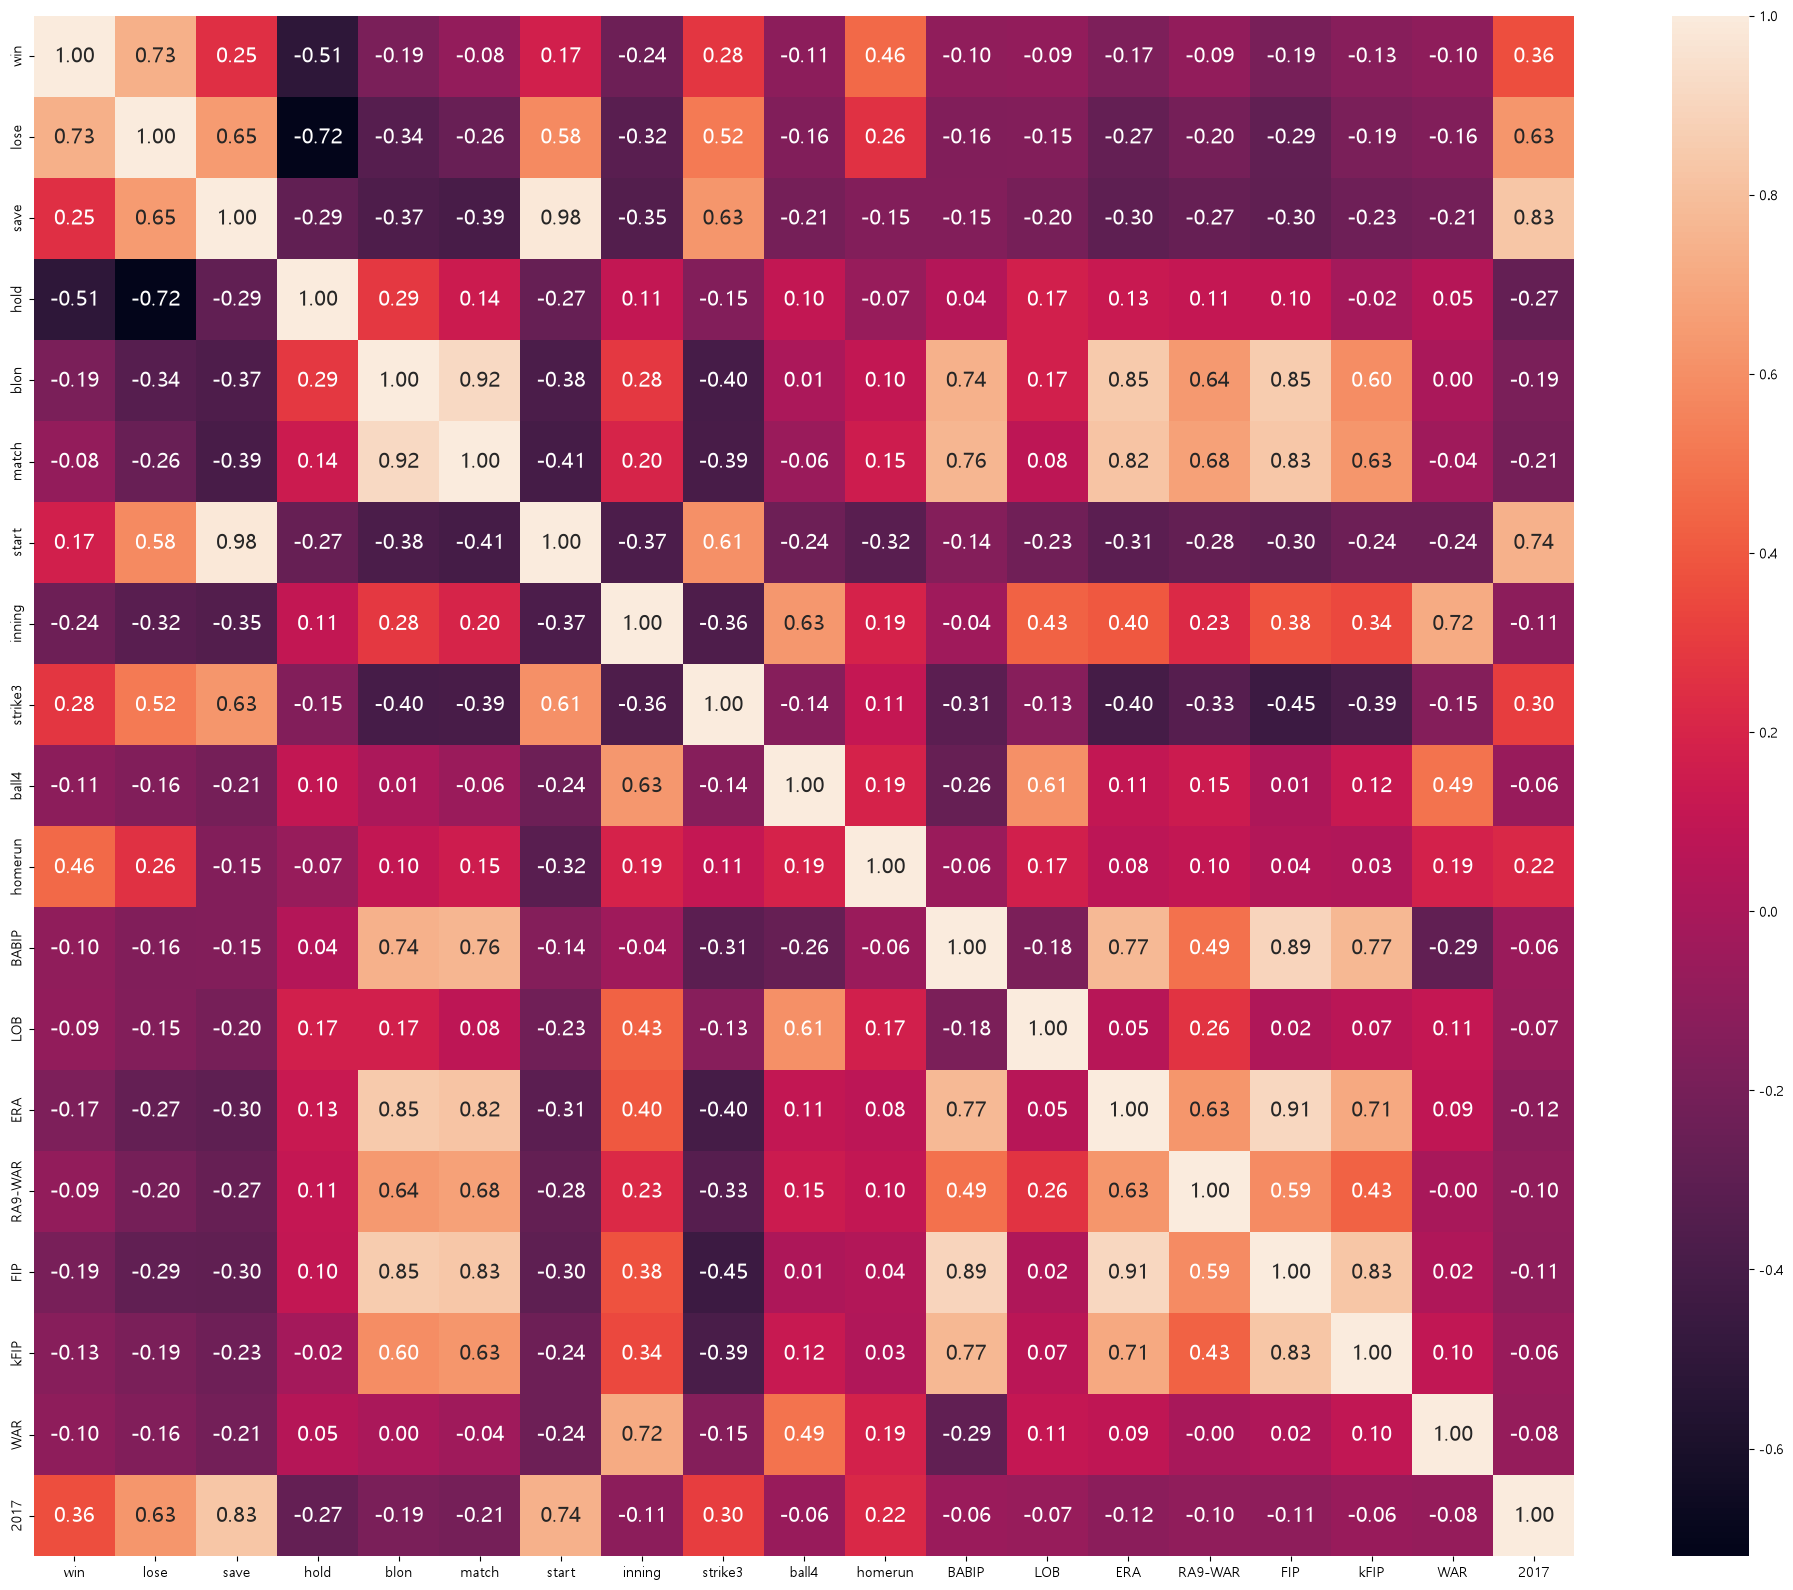

In [114]:
# pip install seaborn
import seaborn as sns

# 피처간의 상관계수 행렬을 계산
corr = picher[data.columns].corr(method='pearson')
show_cols = ['win', 'lose', 'save', 'hold', 'blon', 'match', 'start',
            'inning', 'strike3', 'ball4', 'homerun', 'BABIP', 'LOB',
            'ERA', 'RA9-WAR', 'FIP', 'kFIP', 'WAR', '2017']

# corr 행렬 히트맵을 시각화합니다.
# plt.rc('font', family='NanumGothicOTF')

hm = sns.heatmap(corr.values,
            cbar=True,
            annot=True,
            square=True,
            fmt='.2f',
            annot_kws={'size': 15},
            yticklabels=show_cols,
            xticklabels=show_cols)

plt.tight_layout()
plt.show()